<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%9614.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import io
import os
import random
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import torch
from torch import nn, optim
from torchvision import datasets, transforms, models
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print("Пристрій:", device)

Пристрій: mps


# Перетворення, завантажувачі даних та функції навчання

In [ ]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(size=256, scale=(0.8, 1.0)),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(),
    transforms.RandomHorizontalFlip(),
    transforms.CenterCrop(size=224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])

eval_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])

def make_loaders(root, test_root=None, valid_size=0.2, test_size=0.1, batch_size=32):
    train_data = datasets.ImageFolder(root, transform=train_transforms)
    eval_data = datasets.ImageFolder(root, transform=eval_transforms)
    indices = np.random.RandomState(0).permutation(len(train_data)).tolist()
    valid_split = int(np.floor(valid_size * len(indices)))
    if test_root is None:
        test_split = int(np.floor((valid_size + test_size) * len(indices)))
        valid_idx, test_idx, train_idx = indices[:valid_split], indices[valid_split:test_split], indices[test_split:]
        test_set = torch.utils.data.Subset(eval_data, test_idx[:2000])
    else:
        valid_idx, train_idx = indices[:valid_split], indices[valid_split:]
        test_set = datasets.ImageFolder(test_root, transform=eval_transforms)
    print("train / valid / test:", len(train_idx[:10000]), len(valid_idx[:2000]), len(test_set))
    train_loader = torch.utils.data.DataLoader(
        torch.utils.data.Subset(train_data, train_idx[:10000]), batch_size=batch_size, shuffle=True)
    valid_loader = torch.utils.data.DataLoader(
        torch.utils.data.Subset(eval_data, valid_idx[:2000]), batch_size=batch_size)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size)
    return train_loader, valid_loader, test_loader

def evaluate(model, criterion, loader):
    model.eval()
    total_loss, preds, targets = 0.0, [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            output = model(inputs)
            total_loss += criterion(output, labels).item() * len(labels)
            preds.append(output.argmax(dim=1).cpu())
            targets.append(labels.cpu())
    preds, targets = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    return total_loss / len(targets), (preds == targets).mean(), confusion_matrix(targets, preds)

def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def fit(name, model, optimizer, criterion, loaders, epochs=3):
    train_loader, valid_loader, test_loader = loaders
    path = name.replace(' ', '_').replace(',', '').replace('(', '').replace(')', '') + '.pt'
    valid_loss_min, times, history = np.inf, [], []
    for epoch in range(epochs):
        start = time.time()
        model.train()
        train_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)
        valid_loss, valid_acc, _ = evaluate(model, criterion, valid_loader)
        history.append((train_loss, valid_loss, valid_acc))
        saved = ''
        if valid_loss <= valid_loss_min:
            torch.save(model.state_dict(), path)
            valid_loss_min = valid_loss
            saved = ' (модель збережено)'
        times.append(time.time() - start)
        print(f'{name} | епоха {epoch + 1}: train loss {train_loss:.4f}, valid loss {valid_loss:.4f}, '
              f'valid acc {valid_acc:.4f}, {times[-1]:.0f} с{saved}')
    model.load_state_dict(torch.load(path, map_location=device))
    test_loss, test_acc, cm = evaluate(model, criterion, test_loader)
    print(f'{name} | завантажено кращу модель з файлу {path}: test loss {test_loss:.4f}, test acc {test_acc:.4f}')
    return {'model': model, 'optimizer': optimizer, 'path': path, 'history': history, 'test acc': test_acc,
            'test loss': test_loss, 'cm': cm, 'time/epoch, с': np.mean(times), 'trainable': count_trainable(model),
            'best valid loss': valid_loss_min}

def classifier_head(in_features, hidden=460, log_softmax=True):
    layers = [nn.Linear(in_features, hidden), nn.ReLU(), nn.Dropout(0.4), nn.Linear(hidden, 2)]
    if log_softmax:
        layers.append(nn.LogSoftmax(dim=1))
    return nn.Sequential(*layers)

def table(runs):
    return pd.DataFrame({n: {'valid loss': r['best valid loss'], 'test acc': r['test acc'],
                             'test loss': r['test loss'], 'параметрів навчається': r['trainable'],
                             'с/епоха': r['time/epoch, с']} for n, r in runs.items()}).T

def curves(runs):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for n, r in runs.items():
        h = np.array(r['history'])
        axes[0].plot(range(1, len(h) + 1), h[:, 1], marker='o', label=n)
        axes[1].plot(range(1, len(h) + 1), h[:, 2], marker='o', label=n)
    axes[0].set_title('Втрати на валідації')
    axes[1].set_title('Точність на валідації')
    for ax in axes:
        ax.set_xlabel('Епоха')
        ax.grid(alpha=0.3)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

Для економії часу використовуються 10 000 зображень для навчання та по 2000 для валідації й тесту. Перетворення з теорії (`RandomResizedCrop`, `RandomRotation`, `ColorJitter`, `RandomHorizontalFlip`) застосовуються лише до навчальних даних, а для валідації та тесту лише змінюється розмір і береться обрізання по центру. Окремі набори `ImageFolder` для навчання та оцінки створюються з однаковим порядком індексів, щоб до валідаційних і тестових зображень не застосовувалась аугментація. Модель зберігається у файл `.pt` через `torch.save(model.state_dict(), path)` кожного разу, коли втрата на валідації зменшується або не збільшується, а після навчання кращі параметри завантажуються назад через `load_state_dict(torch.load(path))`, і тест проводиться саме на завантаженій моделі.

# Завдання 1. Виявлення малярії: покращення моделі

> Спробуйте покращити отримані результати в задачі про виявлення малярії (модель наведена у теоретичному матеріалі), використовуючи різні моделі (архітектури), підходи, технології. Спробуйте внести зміни в оптимізатор, попередньо підготовлену модель та функцію втрат. Ви можете додати більше перетворень або навіть додати більше шарів до повністю з'єднаних шарів.

(148, 142, 3)


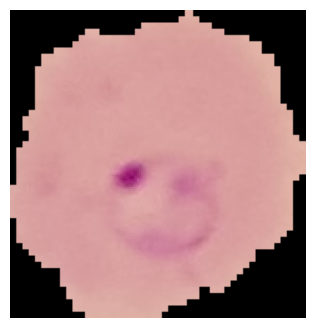

train / valid / test: 10000 2000 2000
['Parasitized', 'Uninfected']


In [ ]:
if not os.path.exists('cell_images'):
    urllib.request.urlretrieve('https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip', 'cell_images.zip')
    zipfile.ZipFile('cell_images.zip').extractall('.')
img_dir = 'cell_images'

x = Image.open(img_dir + '/Parasitized/' + sorted(os.listdir(img_dir + '/Parasitized'))[0])
print(np.array(x).shape)
plt.figure(figsize=(4, 4))
plt.imshow(x)
plt.axis('off')
plt.show()

malaria_loaders = make_loaders(img_dir)
print(malaria_loaders[0].dataset.dataset.classes)

Набір даних завантажується з ресурсу NIH, вказаного в теоретичних відомостях. Він містить 27 558 зображень клітин у двох папках: `Parasitized` (заражені) та `Uninfected` (здорові). Як в теорії, 20% даних відводиться на валідацію, 10% на тест, решта на навчання.

# Базова модель з теорії: densenet121 із замороженими шарами

In [ ]:
def densenet_baseline():
    model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
    for param in model.parameters():
        param.requires_grad = False
    model.classifier = classifier_head(1024)
    return model.to(device)

torch.manual_seed(0)
model = densenet_baseline()
malaria = {}
malaria['densenet121 (з теорії)'] = fit('malaria densenet121 baseline', model,
                                        optim.Adam(model.classifier.parameters(), lr=0.003), nn.NLLLoss(), malaria_loaders)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /Users/yehoryevtushenko/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


0.4%

0.8%

1.2%

1.6%

2.0%

... (242 outputs left out)

malaria densenet121 baseline | епоха 1: train loss 0.3586, valid loss 0.2252, valid acc 0.9075, 88 с (модель збережено)


malaria densenet121 baseline | епоха 2: train loss 0.2956, valid loss 0.2105, valid acc 0.9145, 78 с (модель збережено)


malaria densenet121 baseline | епоха 3: train loss 0.2772, valid loss 0.2173, valid acc 0.9145, 78 с


malaria densenet121 baseline | завантажено кращу модель з файлу malaria_densenet121_baseline.pt: test loss 0.2032, test acc 0.9265


Базова модель із теорії: заздалегідь навчена на ImageNet densenet121, усі її параметри заморожені (`requires_grad = False`), а замість останнього шару стоїть власний класифікатор 1024 → 460 → 2 з ReLU, Dropout 0.4 і LogSoftmax. Втрата NLLLoss, оптимізатор Adam з `lr=0.003`, навчається лише класифікатор (472 тис. параметрів). Ця модель дала точність 0.9265 на тесті. Це точка відліку для всіх подальших змін.

# Інші архітектури

In [ ]:
def with_new_head(arch):
    if arch == 'resnet18':
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    elif arch == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    for param in model.parameters():
        param.requires_grad = False
    model.fc = classifier_head(model.fc.in_features)
    return model.to(device), model.fc

def mobilenet_model():
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    for param in model.parameters():
        param.requires_grad = False
    model.classifier = classifier_head(1280)
    return model.to(device)

for arch in ['resnet18', 'resnet50']:
    torch.manual_seed(0)
    model, head = with_new_head(arch)
    malaria[arch] = fit('malaria ' + arch, model, optim.Adam(head.parameters(), lr=0.003), nn.NLLLoss(), malaria_loaders)

torch.manual_seed(0)
model = mobilenet_model()
malaria['mobilenet_v2'] = fit('malaria mobilenet_v2', model, optim.Adam(model.classifier.parameters(), lr=0.003),
                              nn.NLLLoss(), malaria_loaders)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/yehoryevtushenko/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


0.3%

0.6%

0.8%

1.1%

1.4%

... (1,254 outputs left out)

malaria mobilenet_v2 | епоха 1: train loss 0.3438, valid loss 0.2679, valid acc 0.9035, 39 с (модель збережено)


malaria mobilenet_v2 | епоха 2: train loss 0.3167, valid loss 0.2598, valid acc 0.8915, 39 с (модель збережено)


malaria mobilenet_v2 | епоха 3: train loss 0.2945, valid loss 0.2399, valid acc 0.9050, 43 с (модель збережено)


malaria mobilenet_v2 | завантажено кращу модель з файлу malaria_mobilenet_v2.pt: test loss 0.2473, test acc 0.9005


Інші заздалегідь навчені архітектури з тим самим класифікатором і тими самими налаштуваннями: resnet18 дала 0.897, mobilenet_v2 0.9005, resnet50 0.924, тобто жодна не перевершила densenet121 (0.9265). У resnet18 втрата на валідації на третій епосі різко зросла (з 0.25 до 0.36), тож вона нестабільніша за інші. Різниця між densenet121 і resnet50 (0.2 п.п.) менша за випадковий розкид одного запуску на 2000 зображеннях, тому вважати одну з них кращою не можна.

# Зміна оптимізатора, функції втрат і класифікатора

In [ ]:
torch.manual_seed(0)
model = densenet_baseline()
malaria['densenet121, SGD з моментом'] = fit('malaria densenet121 SGD', model,
    optim.SGD(model.classifier.parameters(), lr=0.01, momentum=0.9), nn.NLLLoss(), malaria_loaders)

torch.manual_seed(0)
model = densenet_baseline()
model.classifier = nn.Sequential(
    nn.Linear(1024, 512), nn.ReLU(), nn.Dropout(0.4),
    nn.Linear(512, 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 2)).to(device)
malaria['densenet121, глибший класифікатор, AdamW, label smoothing'] = fit(
    'malaria densenet121 deep head', model,
    optim.AdamW(model.classifier.parameters(), lr=0.001, weight_decay=0.01),
    nn.CrossEntropyLoss(label_smoothing=0.1), malaria_loaders)

malaria densenet121 SGD | епоха 1: train loss 0.3614, valid loss 0.2277, valid acc 0.9050, 77 с (модель збережено)


malaria densenet121 SGD | епоха 2: train loss 0.3117, valid loss 0.2185, valid acc 0.9115, 77 с (модель збережено)


malaria densenet121 SGD | епоха 3: train loss 0.2742, valid loss 0.2203, valid acc 0.9155, 78 с


malaria densenet121 SGD | завантажено кращу модель з файлу malaria_densenet121_SGD.pt: test loss 0.2101, test acc 0.9250


malaria densenet121 deep head | епоха 1: train loss 0.4446, valid loss 0.3653, valid acc 0.9080, 79 с (модель збережено)


malaria densenet121 deep head | епоха 2: train loss 0.3909, valid loss 0.3482, valid acc 0.9155, 78 с (модель збережено)


malaria densenet121 deep head | епоха 3: train loss 0.3787, valid loss 0.3330, valid acc 0.9165, 78 с (модель збережено)


malaria densenet121 deep head | завантажено кращу модель з файлу malaria_densenet121_deep_head.pt: test loss 0.3249, test acc 0.9270


Заміна Adam на SGD з моментом 0.9 (`lr=0.01`) дала 0.925, тобто практично той самий результат (0.9265). Глибший класифікатор (1024 → 512 → 128 → 2 з двома Dropout) разом з AdamW (`weight_decay=0.01`) і `CrossEntropyLoss(label_smoothing=0.1)` дав 0.927. Значення втрат у цього варіанту (0.32) більші, ніж в інших, бо label smoothing не дозволяє втраті наблизитись до нуля, тому порівнювати його втрату з іншими не можна, а точність порівнювати можна. Отже, у цій задачі зміна лише оптимізатора, функції втрат або глибини класифікатора при замороженій основі не дала помітного виграшу: усі ці результати лежать у межах близько 0.5 п.п. від базового.

# Донавчання частини згорткових шарів

malaria densenet121 finetune | епоха 1: train loss 0.2504, valid loss 0.1609, valid acc 0.9445, 86 с (модель збережено)


malaria densenet121 finetune | епоха 2: train loss 0.1709, valid loss 0.1368, valid acc 0.9515, 84 с (модель збережено)


malaria densenet121 finetune | епоха 3: train loss 0.1638, valid loss 0.1352, valid acc 0.9510, 83 с (модель збережено)


malaria densenet121 finetune | завантажено кращу модель з файлу malaria_densenet121_finetune.pt: test loss 0.1293, test acc 0.9565
                                                           valid loss  test acc  test loss  параметрів навчається  с/епоха
densenet121 (з теорії)                                         0.2105    0.9265     0.2032               472422.0  81.2239
resnet18                                                       0.2516    0.8970     0.2480               236902.0  38.2946
resnet50                                                       0.1939    0.9240     0.2071               943462.0  74.7251
mobilenet_v2                                                   0.2399    0.9005     0.2473               590182.0  40.2131
densenet121, SGD з моментом                                    0.2185    0.9250     0.2101               472422.0  77.4726
densenet121, глибший класифікатор, AdamW, label smoothing      0.3330    0.9270     0.3249               590722.0  78.1690
densenet

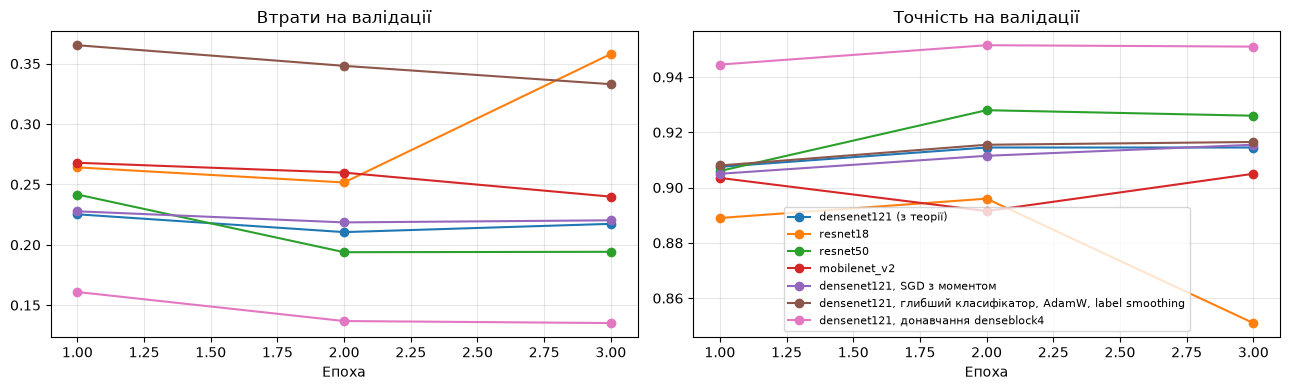

In [ ]:
torch.manual_seed(0)
model = densenet_baseline()
for param in model.features.denseblock4.parameters():
    param.requires_grad = True
for param in model.features.norm5.parameters():
    param.requires_grad = True
optimizer = optim.Adam([
    {'params': model.classifier.parameters(), 'lr': 0.003},
    {'params': list(model.features.denseblock4.parameters()) + list(model.features.norm5.parameters()), 'lr': 0.0001}])
malaria['densenet121, донавчання denseblock4'] = fit('malaria densenet121 finetune', model, optimizer, nn.NLLLoss(), malaria_loaders)

print(table(malaria).round(4).to_string())
curves(malaria)

Єдина зміна, яка дала помітне покращення, це донавчання останнього блоку `denseblock4` разом із `norm5` з меншою швидкістю навчання (`lr=0.0001`, класифікатор залишається з `0.003`). Точність на тесті зросла з 0.9265 до 0.9565 (+3.0 п.п.), втрата на валідації впала з 0.21 до 0.135. Ціна цього: 2.6 млн параметрів, що навчаються, замість 0.47 млн, і трохи більший час епохи (84 с проти 81 с). Тут використано той самий підхід, що в теорії (заморожування основи), але розморожено кінець основи, бо ознаки ImageNet для зображень клітин не ідеальні, і їх варто трохи підлаштувати.

# Збереження контрольної точки та відновлення навчання

In [ ]:
best_name = max(malaria, key=lambda n: malaria[n]['test acc'])
print('Найкраща за точністю на тесті:', best_name)

run = malaria['resnet18']
model, optimizer = run['model'], run['optimizer']
print(list(model.state_dict().keys())[-4:])
print({k: v for k, v in optimizer.state_dict()['param_groups'][0].items() if k != 'params'})

torch.save({'epoch': 3, 'model_state_dict': model.state_dict(), 'optimizer_state_dict': optimizer.state_dict(),
            'loss': run['best valid loss']}, 'checkpoint_resnet18.tar')

torch.manual_seed(1)
new_model, new_head = with_new_head('resnet18')
new_optimizer = optim.Adam(new_head.parameters(), lr=0.003)
print('До завантаження:', evaluate(new_model, nn.NLLLoss(), malaria_loaders[2])[1])

checkpoint = torch.load('checkpoint_resnet18.tar', map_location=device)
new_model.load_state_dict(checkpoint['model_state_dict'])
new_optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
print('Епоха з контрольної точки:', checkpoint['epoch'], ', збережена втрата:', round(checkpoint['loss'], 4))
print('Після завантаження:', evaluate(new_model, nn.NLLLoss(), malaria_loaders[2])[1])

new_model.train()
for inputs, labels in malaria_loaders[0]:
    inputs, labels = inputs.to(device), labels.to(device)
    new_optimizer.zero_grad()
    loss = nn.NLLLoss()(new_model(inputs), labels)
    loss.backward()
    new_optimizer.step()
print('Після ще однієї епохи навчання:', evaluate(new_model, nn.NLLLoss(), malaria_loaders[2])[1])

Найкраща за точністю на тесті: densenet121, донавчання denseblock4
['fc.0.weight', 'fc.0.bias', 'fc.3.weight', 'fc.3.bias']
{'lr': 0.003, 'betas': (0.9, 0.999), 'eps': 1e-08, 'weight_decay': 0, 'amsgrad': False, 'maximize': False, 'foreach': None, 'capturable': False, 'differentiable': False, 'fused': None, 'decoupled_weight_decay': False}


До завантаження: 0.5005
Епоха з контрольної точки: 3 , збережена втрата: 0.2516


Після завантаження: 0.897


Після ще однієї епохи навчання: 0.9075


Контрольна точка зберігає не лише параметри моделі, а й стан оптимізатора, номер епохи та втрату. У словнику `state_dict` лише шари з параметрами (для resnet18 це `fc.0` і `fc.3` нового класифікатора), а `optimizer.state_dict()` містить гіперпараметри (`lr`, `betas`, `weight_decay`). Нова модель з випадковим класифікатором до завантаження дає точність 0.5005, після `load_state_dict` з контрольної точки 0.897, що збігається зі збереженою моделлю, а ще одна епоха навчання з відновленим оптимізатором (після `model.train()`) піднімає її до 0.9075.

# Передбачення для окремих зображень

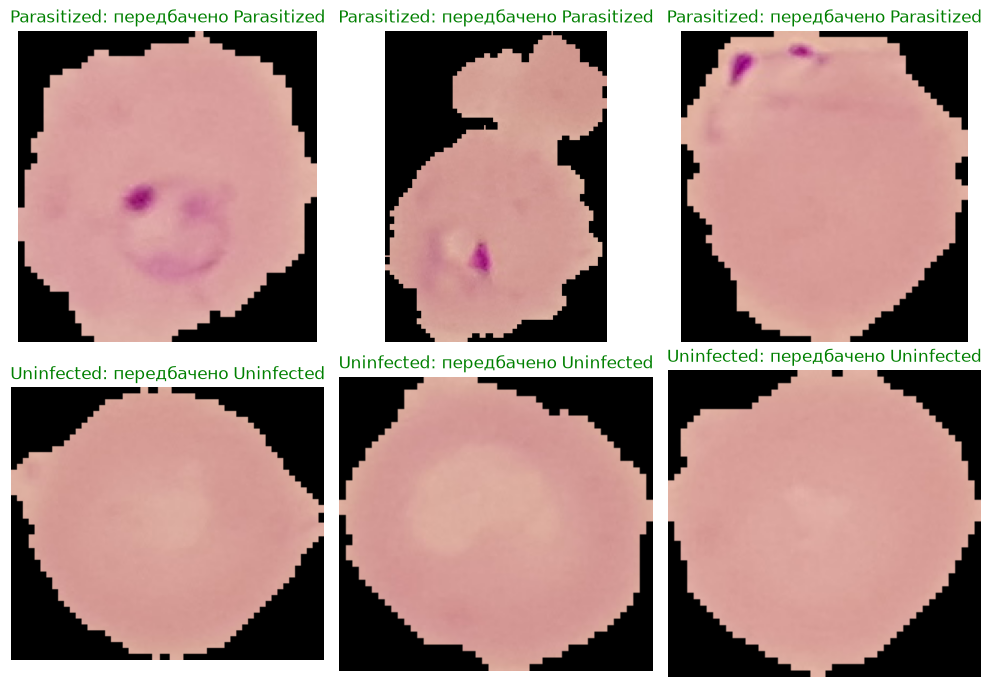

In [ ]:
def load_input_image(img_path):
    image = Image.open(img_path)
    prediction_transform = transforms.Compose([
        transforms.Resize(size=(224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)])
    return prediction_transform(image)[:3, :, :].unsqueeze(0)

def predict(model, class_names, img_path):
    img = load_input_image(img_path)
    model = model.cpu()
    model.eval()
    idx = torch.argmax(model(img))
    return class_names[idx]

best_model = malaria[best_name]['model']
best_model.load_state_dict(torch.load(malaria[best_name]['path'], map_location='cpu'))
class_names = ['Parasitized', 'Uninfected']
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for row, cls in enumerate(class_names):
    files = sorted(os.listdir(img_dir + '/' + cls))[:3]
    for col, f in enumerate(files):
        path = img_dir + '/' + cls + '/' + f
        answer = predict(best_model, class_names, path)
        axes[row, col].imshow(Image.open(path))
        axes[row, col].set_title(f'{cls}: передбачено {answer}', color='green' if answer == cls else 'red')
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()
_ = best_model.to(device)

Збережена найкраща модель завантажується з файлу, переноситься на процесор (`model.cpu()`, `model.eval()`), і для трьох заражених та трьох здорових клітин показується передбачений клас: зелений заголовок означає правильне передбачення, червоний помилку.

# Завдання 2. Рентгенівські знімки легенів: норма та пневмонія

> Спробуйте вирішити завдання аналізу рентгенівського знімку легенів та класифікувати їх на класи: норма та пневмонія. Завантажте датасет за посиланням та проаналізуйте додаткову інформацію: https://www.kaggle.com/paultimothymooney/chest-xray-pneumonia

In [ ]:
if not os.path.exists('chest_xray'):
    base = 'https://huggingface.co/datasets/hf-vision/chest-xray-pneumonia/resolve/main/data/'
    parts = {'train': ['train-%05d-of-00007' % i for i in range(7)], 'test': ['test-00000-of-00001']}
    class_folders = ['NORMAL', 'PNEUMONIA']
    for split, names in parts.items():
        for cls in class_folders:
            os.makedirs(f'chest_xray/{split}/{cls}', exist_ok=True)
        counter = 0
        for part in names:
            urllib.request.urlretrieve(base + part + '.parquet', part + '.parquet')
            frame = pd.read_parquet(part + '.parquet')
            for item, label in zip(frame['image'], frame['label']):
                img = Image.open(io.BytesIO(item['bytes'])).convert('RGB')
                scale = 256 / min(img.size)
                img = img.resize((round(img.size[0] * scale), round(img.size[1] * scale)))
                img.save(f'chest_xray/{split}/{class_folders[label]}/{counter}.jpg', quality=92)
                counter += 1
            os.remove(part + '.parquet')

for split in ['train', 'test']:
    print(split, {cls: len(os.listdir(f'chest_xray/{split}/{cls}')) for cls in ['NORMAL', 'PNEUMONIA']})

xray_loaders = make_loaders('chest_xray/train', test_root='chest_xray/test')

train {'NORMAL': 1341, 'PNEUMONIA': 3875}
test {'NORMAL': 234, 'PNEUMONIA': 390}
train / valid / test: 4173 1043 624


Набір даних Chest X-Ray Images (Pneumonia) з Kaggle недоступний без входу в обліковий запис, тому тут використовується його копія з тим самим вмістом (5216 навчальних та 624 тестових знімків), яка завантажується і розкладається у ті самі папки `train/NORMAL`, `train/PNEUMONIA`, `test/NORMAL`, `test/PNEUMONIA`. Для економії часу знімки зменшуються так, щоб менша сторона дорівнювала 256 пікселів. Валідаційна папка набору містить лише 16 знімків, тому для валідації береться 20% навчальної папки, а як тест використовується офіційна тестова папка. Класи незбалансовані: пневмонія становить близько трьох чвертей навчальних знімків, тому крім точності розглядається матриця помилок.

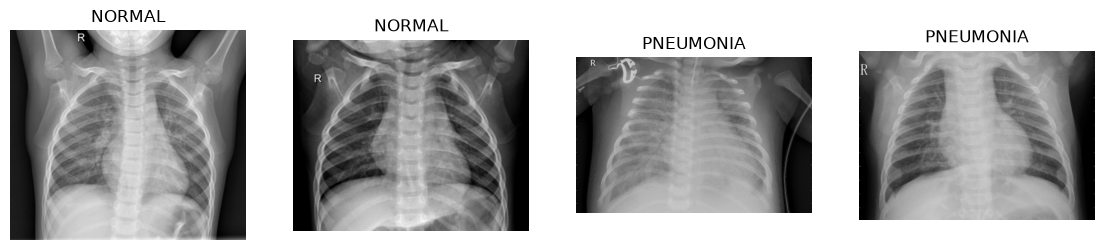

xray densenet121 baseline | епоха 1: train loss 0.4110, valid loss 0.1561, valid acc 0.9386, 38 с (модель збережено)


xray densenet121 baseline | епоха 2: train loss 0.1929, valid loss 0.1940, valid acc 0.9243, 34 с


xray densenet121 baseline | епоха 3: train loss 0.1845, valid loss 0.2862, valid acc 0.8792, 34 с


xray densenet121 baseline | завантажено кращу модель з файлу xray_densenet121_baseline.pt: test loss 0.4149, test acc 0.8157


xray resnet18 | епоха 1: train loss 0.3494, valid loss 0.1812, valid acc 0.9310, 16 с (модель збережено)


xray resnet18 | епоха 2: train loss 0.2282, valid loss 0.3328, valid acc 0.8591, 15 с


xray resnet18 | епоха 3: train loss 0.2337, valid loss 0.1665, valid acc 0.9406, 16 с (модель збережено)


xray resnet18 | завантажено кращу модель з файлу xray_resnet18.pt: test loss 0.5235, test acc 0.7917


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (cls, i) in zip(axes, [('NORMAL', 0), ('NORMAL', 1), ('PNEUMONIA', 0), ('PNEUMONIA', 1)]):
    ax.imshow(Image.open(f'chest_xray/train/{cls}/{sorted(os.listdir("chest_xray/train/" + cls))[i]}'), cmap='gray')
    ax.set_title(cls)
    ax.axis('off')
plt.show()

xray = {}
torch.manual_seed(0)
model = densenet_baseline()
xray['densenet121 (з теорії)'] = fit('xray densenet121 baseline', model,
                                     optim.Adam(model.classifier.parameters(), lr=0.003), nn.NLLLoss(), xray_loaders)

torch.manual_seed(0)
model, head = with_new_head('resnet18')
xray['resnet18'] = fit('xray resnet18', model, optim.Adam(head.parameters(), lr=0.003), nn.NLLLoss(), xray_loaders)

Той самий конвеєр застосовано до рентгенівських знімків. Базова densenet121 показала на валідації 0.94 після першої епохи, але далі валідація погіршувалась, і на тесті збережена модель дала лише 0.8157; resnet18 дала 0.7917. Втрата та точність на валідації (взятій з навчальної папки) помітно кращі, ніж на офіційному тесті, тобто тестовий набір для моделей складніший за валідаційний.

Кількість знімків у навчальній вибірці (норма, пневмонія): [1072 3101] , ваги класів: [1.946 0.673]


xray densenet121 weighted | епоха 1: train loss 0.3770, valid loss 0.2048, valid acc 0.8869, 34 с (модель збережено)


xray densenet121 weighted | епоха 2: train loss 0.2122, valid loss 0.2736, valid acc 0.9319, 34 с


xray densenet121 weighted | епоха 3: train loss 0.2176, valid loss 0.3875, valid acc 0.9080, 34 с


xray densenet121 weighted | завантажено кращу модель з файлу xray_densenet121_weighted.pt: test loss 0.3020, test acc 0.8814


xray densenet121 finetune | епоха 1: train loss 0.3011, valid loss 0.1005, valid acc 0.9636, 37 с (модель збережено)


xray densenet121 finetune | епоха 2: train loss 0.1196, valid loss 0.0865, valid acc 0.9693, 37 с (модель збережено)


xray densenet121 finetune | епоха 3: train loss 0.1020, valid loss 0.0719, valid acc 0.9712, 37 с (модель збережено)


xray densenet121 finetune | завантажено кращу модель з файлу xray_densenet121_finetune.pt: test loss 0.6328, test acc 0.8446
                                     valid loss  test acc  test loss  параметрів навчається  с/епоха
densenet121 (з теорії)                   0.1561    0.8157     0.4149               472422.0  35.0643
resnet18                                 0.1665    0.7917     0.5235               236902.0  15.6243
densenet121, зважена функція втрат       0.2048    0.8814     0.3020               472422.0  33.8036
densenet121, донавчання denseblock4      0.0719    0.8446     0.6328              2632550.0  36.7063


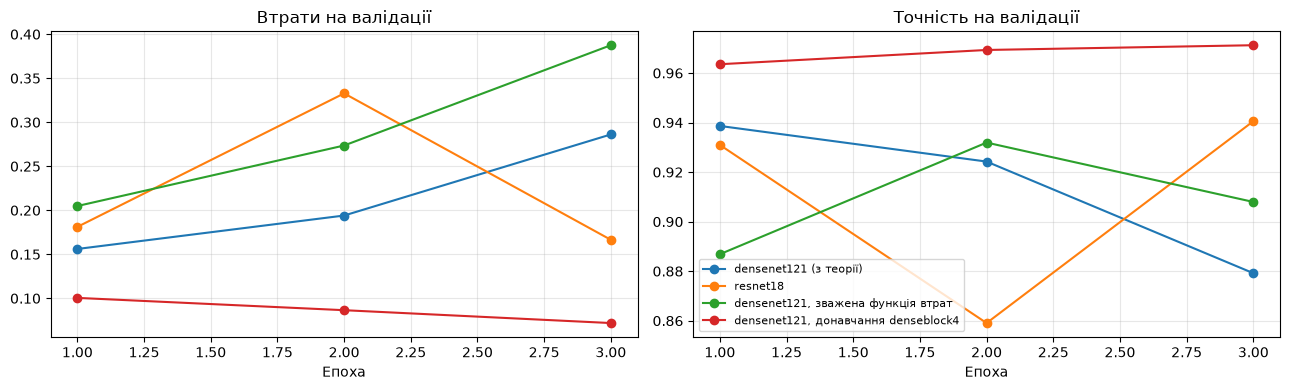

                                     точність  recall норма  recall пневмонія  precision пневмонія  пропущено пневмоній  хибні тривоги
densenet121 (з теорії)                 0.8157        0.5684            0.9641               0.7883                 14.0          101.0
resnet18                               0.7917        0.4744            0.9821               0.7569                  7.0          123.0
densenet121, зважена функція втрат     0.8814        0.8547            0.8974               0.9115                 40.0           34.0
densenet121, донавчання denseblock4    0.8446        0.5897            0.9974               0.8021                  1.0           96.0


In [ ]:
train_labels = np.array([s[1] for s in xray_loaders[0].dataset.dataset.samples])[xray_loaders[0].dataset.indices]
counts = np.bincount(train_labels)
class_weights = torch.tensor(counts.sum() / (2.0 * counts), dtype=torch.float32).to(device)
print('Кількість знімків у навчальній вибірці (норма, пневмонія):', counts, ', ваги класів:', class_weights.cpu().numpy().round(3))

torch.manual_seed(0)
model = densenet_baseline()
xray['densenet121, зважена функція втрат'] = fit('xray densenet121 weighted', model,
    optim.Adam(model.classifier.parameters(), lr=0.003), nn.NLLLoss(weight=class_weights), xray_loaders)

torch.manual_seed(0)
model = densenet_baseline()
for param in model.features.denseblock4.parameters():
    param.requires_grad = True
for param in model.features.norm5.parameters():
    param.requires_grad = True
optimizer = optim.Adam([
    {'params': model.classifier.parameters(), 'lr': 0.003},
    {'params': list(model.features.denseblock4.parameters()) + list(model.features.norm5.parameters()), 'lr': 0.0001}])
xray['densenet121, донавчання denseblock4'] = fit('xray densenet121 finetune', model, optimizer, nn.NLLLoss(), xray_loaders)

print(table(xray).round(4).to_string())
curves(xray)

rows = {}
for n, r in xray.items():
    tn, fp, fn, tp = r['cm'].ravel()
    rows[n] = {'точність': r['test acc'], 'recall норма': tn / (tn + fp), 'recall пневмонія': tp / (tp + fn),
               'precision пневмонія': tp / (tp + fp), 'пропущено пневмоній': fn, 'хибні тривоги': fp}
print(pd.DataFrame(rows).T.round(4).to_string())

Зважена функція втрат (`NLLLoss` з вагами класів, обернено пропорційними їх частоті: 1.95 для норми та 0.67 для пневмонії) дала найвищу точність на тесті 0.8814 і найбільш збалансований результат: recall норми 0.855, recall пневмонії 0.897, precision пневмонії 0.912. Базова модель майже не помиляється на пневмонії (recall 0.964), але має багато хибних тривог (101 зі 234 здорових знімків названо пневмонією, recall норми 0.568). Донавчання `denseblock4` дало найнижчу втрату на валідації (0.072, точність 0.971), але на тесті точність лише 0.8446: пропущено тільки 1 пневмонію (recall 0.997), проте 96 здорових знімків названо пневмонією. Результати одного запуску з 3 епох на 624 тестових знімках можуть коливатись приблизно на ±1.5 п.п., тож різниці між близькими варіантами не є надійними, а от різниця між збалансованою моделлю і рештою (по 40 проти 1–14 пропущених пневмоній і 34 проти 96–123 хибних тривог) вказує на реальний компроміс між двома типами помилок.

# Висновки

У цьому практикумі ми навчились зберігати параметри моделі PyTorch через `torch.save(model.state_dict(), path)`, завантажувати їх через `model.load_state_dict(torch.load(path))`, зберігати та відновлювати контрольну точку з оптимізатором, і використовувати заздалегідь навчені моделі в transfer learning для виявлення малярії та аналізу рентгенівських знімків легенів. Метою роботи було засвоїти методику збереження та завантаження моделей у PyTorch, і її досягнуто. Усі експерименти виконано на підвибірці (10 000 зображень для навчання, для рентгену доступні 4173) по 3 епохи одним запуском.

**Виявлення малярії.** Найкращою є densenet121 із донавчанням останнього блоку `denseblock4`: точність на тесті 0.9565 проти 0.9265 у базової моделі з теорії. Заміна оптимізатора на SGD (0.925), глибший класифікатор з AdamW і label smoothing (0.927), інші архітектури із замороженою основою (resnet50 0.924, mobilenet_v2 0.9005, resnet18 0.897) не дали покращення понад розкид одного запуску. Отже, для малярії оптимальна densenet121 з частково розмороженою основою, але за швидкістю вона не найкраща: resnet18 і mobilenet_v2 навчаються вдвічі швидше (близько 40 с на епоху проти 84 с), хоч і дають меншу точність.

**Рентгенівські знімки.** Найвищу точність на тесті дала densenet121 із зваженою функцією втрат: 0.8814, з recall норми 0.855 і recall пневмонії 0.897. Донавчання `denseblock4` дало кращу валідацію (0.971), але на тесті 0.8446, зате з найменшою кількістю пропущених пневмоній (1 із 390). Тому вибір залежить від того, яка помилка вважається небезпечнішою: якщо пропуск пневмонії гірший за хибну тривогу, оптимальним буде донавчання, якщо потрібен баланс, то зважена втрата. Загалом точність на тесті (0.79–0.88) значно нижча, ніж на валідації (до 0.97), і висновки про вибір моделі зроблено за одним запуском на невеликому тесті, тому їх слід вважати орієнтовними.

# Контрольні питання

**1. Як проводиться збереження коефіцієнтів моделі у PyTorch?**

Для збереження використовується функція `torch.save`, яка за допомогою утиліти pickle серіалізує об'єкт на диск. Коефіцієнти моделі, що навчаються (ваги та зміщення), містяться в `state_dict`: це словник Python, який відображає кожен шар у його тензор параметрів, до якого також потрапляють зареєстровані буфери, наприклад `running_mean` у batchnorm. Рекомендований спосіб полягає в збереженні лише навчених параметрів: `torch.save(model.state_dict(), "model.pt")`, зазвичай із розширенням `.pt` або `.pth`. Так можна зберегти й цілу модель командою `torch.save(model, PATH)`, але тоді серіалізовані дані прив'язані до конкретних класів та структури каталогів, бо pickle зберігає шлях до файлу з класом, а не сам клас. Для відновлення навчання зберігають загальну контрольну точку: словник із `model.state_dict()`, `optimizer.state_dict()`, номером епохи, значенням втрат та іншими потрібними елементами, зазвичай із розширенням `.tar`. Якщо модель складається з кількох модулів (GAN, ансамбль), у такий словник записують `state_dict` кожної моделі та відповідного оптимізатора. Модель `DataParallel` зберігають через `model.module.state_dict()`.

**2. Як завантажити коефіцієнти попередньо збереженої моделі у PyTorch?**

Спочатку створюється об'єкт моделі того самого класу, потім файл десеріалізується через `torch.load`, а отриманий словник передається в `model.load_state_dict`: `model = TheModelClass(); model.load_state_dict(torch.load("model.pt"))`. Функція `load_state_dict` приймає саме словник, а не шлях до файлу, тому передати їй `PATH` напряму не можна. Після завантаження треба викликати `model.eval()`, щоб шари dropout та batch normalization працювали в режимі оцінювання, інакше результати будуть суперечливими, а для відновлення навчання викликається `model.train()`. Якщо збережено цілу модель, використовується `model = torch.load(PATH)`, причому клас моделі має бути визначений. Контрольна точка завантажується так само: після створення моделі та оптимізатора з `torch.load` читається словник, з якого `load_state_dict` відновлює модель і оптимізатор, а також беруться збережені епоха та втрати. Для завантаження на інший пристрій у `torch.load` вказується `map_location`, наприклад `torch.device('cpu')` для моделі, навченої на GPU, або `"cuda:0"` для моделі, збереженої на CPU, після чого модель переноситься на пристрій через `model.to(device)`. Якщо в `state_dict` ключі не збігаються з моделлю (transfer learning, часткове завантаження), у `load_state_dict` задається `strict=False`.